# Literature RAG: main implementation and recorded runs

This notebook walks through real source preparation, retrieval, reader training,
evaluation and source citation checks. The main algorithms and training loops
are directly visible below, followed by executed data/retrieval outputs and
actual recorded model receipts. No source is encoded or hidden in a bootstrap.

Full T5 training is running separately. Its results are not available yet.
The small CPU train/save/reload run is labelled as a mechanics check, not a QA
benchmark. Historical reader failures remain visible in the analysis notebooks.

Use a fresh environment: `pip install -e ".[reader,models,notebook]"`.
Function cells identify their production source snapshot. Aliases avoid name
collisions, neural imports are lazy, and inline training hashes this notebook.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from types import SimpleNamespace
from collections import Counter
from dataclasses import dataclass, asdict
from functools import lru_cache
import collections, csv, hashlib, html, io, json, math, random, re, statistics, string, subprocess, sys, time, zipfile
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, HTML, SVG
ROOT=Path.cwd().resolve()
if not (ROOT/"src").is_dir(): ROOT=ROOT.parent
assert (ROOT/"src").is_dir(), "Run in this repository"
FIGURES=ROOT/"assets/plots"
FIGURES.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({"svg.fonttype":"none", "font.size":10, "axes.spines.top":False, "axes.spines.right":False})
def sha(raw):
    return hashlib.sha256(raw).hexdigest()
def read_json(relative):
    return json.loads((ROOT/relative).read_text(encoding="utf-8"))
def table(rows,columns,caption):
    header="".join("<th>"+html.escape(str(c))+"</th>" for c in columns)
    body="".join("<tr>"+"".join("<td>"+html.escape(str(r.get(c,"")))+"</td>" for c in columns)+"</tr>" for r in rows)
    display(HTML("<table><caption>"+html.escape(caption)+"</caption><thead><tr>"+header+"</tr></thead><tbody>"+body+"</tbody></table>"))
def show_figure(fig,name):
    fig.tight_layout()
    fig.savefig(FIGURES/(name+".png"),dpi=160)
    fig.savefig(FIGURES/(name+".svg"))
    display(SVG((FIGURES/(name+".svg")).read_text(encoding="utf-8")))
    plt.close(fig)
print("Analysis kernel ready. No model weights loaded.")


Analysis kernel ready. No model weights loaded.


In [2]:
NOTEBOOK_PATH=ROOT/"notebooks/00_main_literature_rag.ipynb"
DATA=ROOT/"data"
STAGED=DATA/"interim/v5-fairytale-cpu"
PROTOCOL=ROOT/"docs/v5-training-protocol.json"
RIGHTS=ROOT/"docs/v5-source-rights.json"
RUN_DIR=ROOT/"models"/("notebook-"+datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
RUN_PREPARE=False
RUN_DOWNLOAD=False
RUN_HYBRID=False
RUN_READER=False
RUN_TRAIN=False
RUN_RERANKER_TRAIN=False
RUN_GENERATED_ANSWER=False
RUN_TEST=False
BOOKS={"pride":{"id":1342,"title":"Pride and Prejudice","author":"Jane Austen","death":1817},
       "frankenstein":{"id":84,"title":"Frankenstein","author":"Mary Shelley","death":1851}}
DENSE_REVISION="1110a243fdf4706b3f48f1d95db1a4f5529b4d41"
RERANKER_REVISION="233902d25c440f23af6f7d6e94d2946bac0bee0a"
MODEL="deepset/minilm-uncased-squad2"
REVISION="934656cdda79824eabf503ed56e15c01ddbdbe3f"
print("Model training/inference and test scoring require explicit switches.")


Model training/inference and test scoring require explicit switches.


## 1. Source preparation and exact passage geometry

The Gutenberg pipeline preserves its original serialization for citation replay.
Docling conversion is opt-in. FairytaleQA uses its edited section text and exact
dataset offsets, not asserted Gutenberg edition offsets. All Lang-origin groups
stay together because the Blue label contains stories from other Lang books.


In [3]:
def strip_gutenberg(text):
    start = re.search(r"\*\*\* START OF (?:THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", text)
    end = re.search(r"\*\*\* END OF (?:THE|THIS) PROJECT GUTENBERG EBOOK", text)
    if not start or not end or end.start() <= start.end():
        raise ValueError("Expected Gutenberg license boundary markers are missing")
    return text[start.end():end.start()].strip()


def write_processed(path,body):
    """Freeze original Windows CRLF-v1 serialization for cross-platform citation replay.

    Existing CRLF in Gutenberg bodies is intentionally preserved by this legacy
    representation. Hash/read offsets use actual postwrite universal-newline text.
    Changing this serialization requires a new representation version and index.
    """
    path.write_text(body,encoding='utf-8',newline='\r\n')


def fetch(acknowledge=False, root=DATA):
    if not acknowledge:
        raise ValueError("Check local copyright law and pass --acknowledge-local-rights")
    records = []
    for key, meta in BOOKS.items():
        url = f"https://www.gutenberg.org/ebooks/{meta['id']}.txt.utf-8"
        req = urllib.request.Request(url, headers={"User-Agent": "LiteraryResearch/0.1"})
        raw = urllib.request.urlopen(req, timeout=60).read()
        body = strip_gutenberg(raw.decode("utf-8-sig"))
        for folder in ("raw", "processed", "external", "interim"):
            (root / folder).mkdir(parents=True, exist_ok=True)
        (root / "raw" / f"{key}.txt").write_bytes(raw)
        write_processed(root / "processed" / f"{key}.txt",body)
        records.append(dict(meta, key=key, url=url, sha256=hashlib.sha256(raw).hexdigest(), bytes=len(raw)))
    (root / "external" / "manifest.json").write_text(json.dumps(records, indent=2), encoding="utf-8")
    return records


def ingest_document(path):
    path = Path(path)
    if path.suffix.lower() in {".txt", ".md"}:
        return path.read_text(encoding="utf-8")
    from docling.document_converter import DocumentConverter
    converted=DocumentConverter().convert(str(path)).document.export_to_markdown()
    if not converted.strip():raise ValueError('Document conversion produced no text')
    return converted


In [4]:
def sha(raw):
    return hashlib.sha256(raw).hexdigest()


def normalized(text):
    return " ".join(re.findall(r"\w+", text.casefold()))


def shingles(text, n=5):
    words = normalized(text).split()
    return {tuple(words[i:i + n]) for i in range(max(0, len(words) - n + 1))}


def duplicate_reason(story, heldout):
    """Compare source text only, never answers or retrieval outcomes."""
    own = shingles(story["text"])
    for other in heldout:
        if normalized(story["id"]) == normalized(other["id"]):
            return other["id"], "title", 1.0
        if normalized(story["text"]) == normalized(other["text"]):
            return other["id"], "text", 1.0
        theirs = shingles(other["text"])
        overlap = len(own & theirs) / max(1, len(own | theirs))
        if overlap >= 0.8:
            return other["id"], "five-token Jaccard", overlap
    return None


def read_sections(path):
    rows = list(csv.DictReader(io.StringIO(path.read_text(encoding="utf-8-sig"))))
    sections, offset = [], 0
    for row in rows:
        text = row["text"]
        if not text.strip():
            raise ValueError(f"Empty source section in {path.name}")
        sections.append({"id": row["section"], "text": text,
                         "start": offset, "end": offset + len(text)})
        offset += len(text) + 2
    if len({s["id"] for s in sections}) != len(sections):
        raise ValueError("Duplicate section IDs")
    return sections


def prepare_fairytale(source, output, rights, protocol):
    source, output = Path(source), Path(output)
    if output.exists():
        raise ValueError("Refusing to overwrite a staged study")
    policy = json.loads(Path(protocol).read_text(encoding="utf-8"))
    rights_path = Path(rights)
    rights = json.loads(rights_path.read_text(encoding="utf-8"))
    dataset = policy["dataset"]
    metadata = list(csv.DictReader((source / "story_meta.csv").open(encoding="utf-8")))
    val = set(dataset["validation_origins"])
    test = set(dataset["test_origins"])
    excluded = set(dataset["excluded_origins"])
    if val & test or (val | test) & excluded:
        raise ValueError("Overlapping source partitions")
    if not val | test <= set(rights["eligible_origins"]):
        raise ValueError("Held out origins require rights verification")
    stories, manifest = [], []
    for row in metadata:
        origin, official = row["origin"], row["split"]
        if origin in excluded or origin not in rights["eligible_origins"]:
            continue
        split = "validation" if origin in val else "test" if origin in test else "train"
        if split == "train" and official != "train":
            continue
        base = source / "data-by-train-split"
        section_path = base / "section-stories" / official / (row["filename"] + "-story.csv")
        qa_path = base / "questions" / official / (row["filename"] + "-questions.csv")
        sections = read_sections(section_path)
        text = "\n\n".join(s["text"] for s in sections)
        story = {"id": row["filename"], "origin": origin, "split": split,
                 "official_split": official, "sections": sections, "text": text,
                 "source_sha256": sha(text.encode()), "qa_path": qa_path,
                 "qa_sha256": sha(qa_path.read_bytes())}
        stories.append(story)
    heldout = [s for s in stories if s["split"] != "train"]
    removed = []
    retained = []
    for story in stories:
        match = duplicate_reason(story, heldout) if story["split"] == "train" else None
        if match:
            removed.append({"id": story["id"], "matches": match[0],
                            "reason": match[1], "overlap": match[2]})
        else:
            retained.append(story)
    output.mkdir(parents=True)
    for story in retained:
        # Store test CSV verbatim without a DictReader or gold inspection.
        split_dir = output / story["split"]
        split_dir.mkdir(exist_ok=True)
        (split_dir / (story["id"] + ".qa.csv")).write_bytes(story.pop("qa_path").read_bytes())
        (split_dir / (story["id"] + ".story.json")).write_text(
            json.dumps(story, ensure_ascii=False), encoding="utf-8", newline="\n")
        manifest.append({k: story[k] for k in ("id", "origin", "split", "official_split",
                                             "source_sha256", "qa_sha256")})
    report = {"protocol_sha256": sha(Path(protocol).read_bytes()),
              "metadata_sha256": sha((source / "story_meta.csv").read_bytes()),
              "rights_sha256": sha(rights_path.read_bytes()),
              "stories": manifest, "removed_train_duplicates": removed,
              "qa_parsed": False, "test_qa_read_as_bytes_only": True}
    (output / "manifest.json").write_text(json.dumps(report, indent=2), encoding="utf-8")
    return report


In [5]:
@dataclass
class Passage:
    id: str
    book: str
    start: int
    end: int
    text: str
    progress: float


def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())


def chunk_book(book, text, words=180, overlap=40):
    if words < 2 or not 0 <= overlap < words:
        raise ValueError("Require words >= 2 and 0 <= overlap < words")
    spans = list(re.finditer(r"\S+", text))
    result = []
    for i in range(0, len(spans), words-overlap):
        j = min(i+words, len(spans))
        start, end = spans[i].start(), spans[j-1].end()
        result.append(Passage(f"{book}:{start}-{end}", book, start, end, text[start:end], i/max(1,len(spans))))
        if j == len(spans):
            break
    return result


In [6]:
policy=read_json("docs/v5-training-protocol.json")
source_revision=policy["dataset"]["revision"]
source_dir=DATA/"external/fairytaleqa"/("FairytaleQAData-"+source_revision)
if RUN_DOWNLOAD:
    import urllib.request
    archive=source_dir.parent/"source.zip"
    archive.parent.mkdir(parents=True,exist_ok=True)
    if not archive.exists():
        url="https://codeload.github.com/uci-soe/FairytaleQAData/zip/"+source_revision
        archive.write_bytes(urllib.request.urlopen(url,timeout=120).read())
    assert sha(archive.read_bytes())=="353ec962a911ea9b2a4fbba2fe9fdebe2a92c392ce4be36194f2062f0ac9a998", "Pinned archive changed"
    if not source_dir.exists():
        with zipfile.ZipFile(archive) as handle:
            handle.extractall(source_dir.parent)
if RUN_PREPARE:
    # Real pinned official source only; the function refuses overwrite.
    prepare_fairytale(source_dir,STAGED,RIGHTS,PROTOCOL)
summary=read_json("docs/data-summary.json")
table([{"split":k,"stories":v["stories"],"metadata QA":v["metadata_qa"],"median words":v["median_words"]}
       for k,v in summary["source_lengths"].items()],
      ["split","stories","metadata QA","median words"],"Actual source metadata; test QA was not parsed")


split,stories,metadata QA,median words
train,74,3314,2214.5
validation,54,2372,1837.0
test,24,325,1040.0
excluded,126,4569,1937.5


## 2. Hybrid search, persistence and cross-book evidence

This is the complete BM25/LSA/pretrained-dense implementation, including reciprocal
rank fusion and safe JSON/NPZ persistence. LSA is a fitted corpus baseline, not a
pretrained language model. Neural search requires an exact embedding revision.
Similarity proposes passages to compare; it does not prove a literary claim.


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize


In [8]:
@lru_cache(maxsize=2)
def encoder(model_name,revision=None):
    from sentence_transformers import SentenceTransformer
    import torch
    torch.set_num_threads(2)
    return SentenceTransformer(model_name,revision=revision,trust_remote_code=False)


@lru_cache(maxsize=2)
def cross_encoder(model_name):
    from sentence_transformers import CrossEncoder
    import torch
    torch.set_num_threads(2)
    revision=RERANKER_REVISION if model_name=='cross-encoder/ms-marco-MiniLM-L-6-v2' else None
    return CrossEncoder(model_name,revision=revision,trust_remote_code=False)


class HybridIndex:
    def __init__(self, passages, backend="lsa", model_name="sentence-transformers/all-MiniLM-L6-v2",model_revision=None):
        if not passages:
            raise ValueError("Cannot index an empty corpus")
        self.passages, self.backend, self.model_name = passages, backend, model_name
        self.model_revision=model_revision or (DENSE_REVISION if model_name=='sentence-transformers/all-MiniLM-L6-v2' else None)
        if backend=='sentence-transformer' and (not self.model_revision or not re.fullmatch(r'[0-9a-f]{40}',self.model_revision)):raise ValueError('Neural embeddings require an exact 40-character model commit revision')
        self.tf = [Counter(tokenize(p.text)) for p in passages]
        self.lengths = np.array([sum(c.values()) for c in self.tf])
        self.avglen = max(1, self.lengths.mean())
        self.df = Counter(t for c in self.tf for t in c)
        if backend == "lsa":
            self.vectorizer = TfidfVectorizer(stop_words="english", min_df=1, sublinear_tf=True)
            matrix = self.vectorizer.fit_transform(p.text for p in passages)
            n = min(128, matrix.shape[0]-1, matrix.shape[1]-1)
            if n < 1:
                raise ValueError("Need two passages and distinct vocabulary terms")
            self.svd = TruncatedSVD(n_components=n, random_state=42)
            self.dense = normalize(self.svd.fit_transform(matrix))
        elif backend == "sentence-transformer":
            self.dense = self._encoder().encode([p.text for p in passages], normalize_embeddings=True)
        else:
            raise ValueError("Unknown embedding backend")

    def _encoder(self):
        revision=getattr(self,'model_revision',None)
        if not revision or not re.fullmatch(r'[0-9a-f]{40}',revision):raise ValueError('Neural index lacks an exact model revision; re-encode it before querying')
        return encoder(self.model_name,revision)

    def search(self, query, k=6, book=None, reranker=None,mode='hybrid',min_dense=None):
        if not isinstance(query,str) or not isinstance(k,int):raise ValueError('Query must be text and k must be an integer')
        if mode not in {'hybrid','bm25','dense'}:raise ValueError('Unknown retrieval mode')
        if not tokenize(query) or k < 1:
            return []
        bm = np.zeros(len(self.passages))
        for term in set(tokenize(query)):
            df = self.df[term]
            idf = math.log(1 + (len(bm)-df+0.5)/(df+0.5))
            f = np.array([c[term] for c in self.tf])
            bm += idf*f*2.5/(f+1.5*(0.25+0.75*self.lengths/self.avglen))
        if self.backend == "lsa":
            q = normalize(self.svd.transform(self.vectorizer.transform([query])))
        else:
            q = self._encoder().encode([query], normalize_embeddings=True)
        dense = (self.dense @ q.T).ravel()
        eligible = [i for i,p in enumerate(self.passages) if (book is None or p.book == book) and (bm[i] > 0 if mode=='bm25' else dense[i]>1e-8 if mode=='dense' else bm[i] > 0 or dense[i] > 1e-8)]
        if min_dense is not None:eligible=[i for i in eligible if dense[i]>=min_dense]
        fused = {i: 0.0 for i in eligible}
        rankings=(bm,dense) if mode=='hybrid' else (bm,) if mode=='bm25' else (dense,)
        for scores in rankings:
            for rank,i in enumerate(sorted(eligible,key=lambda i:(-scores[i],i)),1):
                fused[i] += 1/(60+rank)
        candidates = sorted(eligible,key=lambda i:(-fused[i],i))[:max(k,30) if reranker else k]
        if reranker and candidates:
            scores = cross_encoder(reranker).predict([(query,self.passages[i].text) for i in candidates],batch_size=8,show_progress_bar=False)
            candidates = [i for _,i in sorted(zip(scores,candidates),reverse=True)][:k]
        return [(self.passages[i],fused[i]) for i in candidates[:k]]

    def save(self,path):
        if self.backend=='sentence-transformer' and (not getattr(self,'model_revision',None) or not re.fullmatch(r'[0-9a-f]{40}',self.model_revision)):raise ValueError('Cannot persist neural index without exact embedding revision')
        path.parent.mkdir(parents=True,exist_ok=True)
        metadata={'schema':1,'backend':self.backend,'model_name':self.model_name,'model_revision':getattr(self,'model_revision',None),'chunk_contract':getattr(self,'chunk_contract',None),'passages':[asdict(p) for p in self.passages],'source_hashes':getattr(self,'source_hashes',{})}
        arrays={'dense':self.dense}
        if self.backend=='lsa':
            metadata['vocabulary']=self.vectorizer.vocabulary_
            arrays['idf']=self.vectorizer.idf_
            arrays['components']=self.svd.components_
        buffer=io.BytesIO();np.savez_compressed(buffer,**arrays)
        with zipfile.ZipFile(path,'w',compression=zipfile.ZIP_DEFLATED) as archive:
            archive.writestr('metadata.json',json.dumps(metadata));archive.writestr('arrays.npz',buffer.getvalue())

    @staticmethod
    def load(path,allow_missing_revision=False):
        # No pickle or executable deserialization. Legacy .pkl files require rebuilding.
        try:
            with zipfile.ZipFile(path) as archive:
                if set(archive.namelist())!={'metadata.json','arrays.npz'} or sum(i.file_size for i in archive.infolist())>512_000_000:raise ValueError('Invalid or oversized index archive')
                meta=json.loads(archive.read('metadata.json'))
                if meta.get('schema')!=1 or meta.get('backend') not in {'lsa','sentence-transformer'}:raise ValueError('Unsupported index schema')
                npz=archive.read('arrays.npz')
                with zipfile.ZipFile(io.BytesIO(npz)) as inner:
                    if sum(i.file_size for i in inner.infolist())>512_000_000:raise ValueError('Oversized embedding arrays')
                    for entry in inner.infolist():
                        with inner.open(entry) as file:
                            version=np.lib.format.read_magic(file)
                            shape,_,dtype=np.lib.format.read_array_header_1_0(file) if version==(1,0) else np.lib.format.read_array_header_2_0(file)
                            if dtype.hasobject or np.prod(shape,dtype=object)*dtype.itemsize>512_000_000:raise ValueError('Unsafe embedding array header')
                arrays=np.load(io.BytesIO(npz),allow_pickle=False)
                expected={'dense','idf','components'} if meta['backend']=='lsa' else {'dense'}
                if set(arrays.files)!=expected:raise ValueError('Unexpected index arrays')
                if any(arrays[name].dtype.kind not in 'fiu' or not np.isfinite(arrays[name]).all() for name in arrays.files):raise ValueError('Non-numeric or non-finite index arrays')
                index=HybridIndex.__new__(HybridIndex)
                index.passages=[Passage(**p) for p in meta['passages']]
                if not index.passages:raise ValueError('Empty index corpus')
                index.backend=meta['backend'];index.model_name=meta['model_name']
                index.model_revision=meta.get('model_revision')
                if index.backend=='sentence-transformer' and (not index.model_revision or not re.fullmatch(r'[0-9a-f]{40}',index.model_revision)) and not allow_missing_revision:raise ValueError('Neural index is missing an exact model revision; re-encode legacy artifacts')
                index.source_hashes=meta.get('source_hashes',{})
                index.chunk_contract=meta.get('chunk_contract')
                index.dense=arrays['dense'].copy()
                if index.dense.ndim!=2 or index.dense.shape[0]!=len(index.passages) or not np.isfinite(index.dense).all():raise ValueError('Invalid embedding matrix')
                if len({p.id for p in index.passages})!=len(index.passages):raise ValueError('Duplicate passage identifiers')
                if any(not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]*',p.book) or p.start<0 or p.end<=p.start or len(p.text)!=p.end-p.start or not 0<=p.progress<=1 or p.id!=f'{p.book}:{p.start}-{p.end}' for p in index.passages):raise ValueError('Invalid passage offsets')
                index.tf=[Counter(tokenize(p.text)) for p in index.passages]
                index.lengths=np.array([sum(c.values()) for c in index.tf]);index.avglen=max(1,index.lengths.mean());index.df=Counter(t for c in index.tf for t in c)
                if any(book not in {p.book for p in index.passages} for book in index.source_hashes):raise ValueError('Invalid source manifest book identifier')
                if index.backend=='lsa':
                    vocabulary=meta['vocabulary']
                    if not isinstance(vocabulary,dict) or set(vocabulary.values())!=set(range(len(vocabulary))):raise ValueError('Invalid vocabulary indices')
                    if arrays['idf'].shape!=(len(vocabulary),) or arrays['components'].ndim!=2 or arrays['components'].shape!=(index.dense.shape[1],len(vocabulary)):raise ValueError('Embedding/vocabulary shape mismatch')
                    index.vectorizer=TfidfVectorizer(stop_words='english',min_df=1,sublinear_tf=True,vocabulary=meta['vocabulary'])
                    index.vectorizer.idf_=arrays['idf'].copy()
                    index.svd=TruncatedSVD(n_components=arrays['components'].shape[0],random_state=42)
                    index.svd.components_=arrays['components'].copy();index.svd.n_features_in_=len(meta['vocabulary'])
                    if index.svd.components_.shape[1]!=len(meta['vocabulary']):raise ValueError('Vocabulary/component mismatch')
                return index
        except (zipfile.BadZipFile,KeyError,TypeError) as error:raise ValueError('Invalid index; rebuild legacy pickle artifacts instead of loading them') from error

    def verify_sources(self,folder):
        for book,digest in getattr(self,'source_hashes',{}).items():
            path=folder/f'{book}.txt'
            if not path.exists() or hashlib.sha256(path.read_text(encoding='utf-8').encode()).hexdigest()!=digest:raise ValueError(f'Source missing or changed for {book}; rebuild index to restore valid citations')
        for book in {p.book for p in self.passages}:
            path=folder/f'{book}.txt'
            if path.exists():
                text=path.read_text(encoding='utf-8')
                if any(text[p.start:p.end]!=p.text for p in self.passages if p.book==book):raise ValueError(f'Citation/source mismatch for {book}')

    def verify_chunk_contract(self, folder, words, overlap):
        from src.features.build_features import chunk_book
        if getattr(self, 'chunk_contract', None) != {'words': words, 'overlap': overlap}:
            raise ValueError('Index chunk contract differs from the frozen selection')
        expected = [p for book in sorted({p.book for p in self.passages})
                    for p in chunk_book(book, (folder / f'{book}.txt').read_text(encoding='utf-8'), words, overlap)]
        if {p.id: p for p in expected} != {p.id: p for p in self.passages}:
            raise ValueError('Index passages do not satisfy the declared chunk contract')


In [9]:
def thematic_report(index, query, k=2, reranker=None):
    sections = []
    selected = []
    for book in sorted({p.book for p in index.passages}):
        hits = index.search(query,k=k,book=book,reranker=reranker)
        if hits:
            selected.extend(p for p,_ in hits)
            sections.append({"book":book,"evidence":[{"citation":p.id,"text":p.text,"progress":round(p.progress,4),"rrf_score":score} for p,score in hits]})
    positions = {p.id:i for i,p in enumerate(index.passages)}
    connections = []
    for i,left in enumerate(selected):
        for right in selected[i+1:]:
            if left.book != right.book:
                similarity=float(np.dot(index.dense[positions[left.id]],index.dense[positions[right.id]]))
                connections.append({"left":left.id,"right":right.id,"cosine_similarity":similarity})
    connections.sort(key=lambda c:-c['cosine_similarity'])
    return {"query":query,"method":"Per-book hybrid retrieval; excerpts are evidence, not inferred conclusions.","books":sections,"cross_book_connections":connections,"connection_note":"Embedding similarity proposes passages to compare; it does not prove a shared literary interpretation.","abstained":not sections}


def character_arc(index, character, book, k=2,topic=None,mode='hybrid',reranker=None):
    if not isinstance(character,str) or len(character.strip())<2:raise ValueError('Provide a non-empty character name')
    pattern = re.compile(r"\b"+re.escape(character)+r"\b",re.I)
    if not any(p.book==book and pattern.search(p.text) for p in index.passages):
        return {'character':character,'book':book,'stages':[],'abstained':True,'reason':'Character name is not explicitly present in requested source'}
    hits = index.search(character+' '+(topic or ''),k=len(index.passages),book=book,mode=mode,reranker=reranker)
    stages = []
    for lo,hi,name in [(0,1/3,"early"),(1/3,2/3,"middle"),(2/3,1.01,"late")]:
        selected = [(p,s) for p,s in hits if lo<=p.progress<hi and (topic is not None or pattern.search(p.text))][:k]
        stages.append({"stage":name,"evidence":[{"citation":p.id,"text":p.text,'explicit_name_mention':bool(pattern.search(p.text)),'attribution':'Explicit name occurs in passage; speaker is not resolved' if pattern.search(p.text) else 'Candidate thematic passage; character attribution is unverified'} for p,s in sorted(selected,key=lambda x:x[0].start)]})
    return {"character":character,"book":book,'topic':topic,"stages":stages,'abstained':False,"note":"Chronological candidate evidence, not an inferred psychological arc. Topic mode can retrieve implicit references but marks their attribution unverified."}


In [10]:
if RUN_HYBRID:
    index=HybridIndex.load(ROOT/"models/v2-96.lrag")
    index.verify_sources(DATA/"processed")
    comparison=thematic_report(index,"responsibility and consequences",k=2)
    print({"books":len(comparison["books"]),"connections":len(comparison["cross_book_connections"]),"abstained":comparison["abstained"]})
else:
    print("Neural hybrid search not rerun. Its complete implementation is visible above.")


Neural hybrid search not rerun. Its complete implementation is visible above.


## 3. Real QA, question-aware sections and answer metrics

The story is given, so this evaluates within-story retrieval rather than global
book routing. Gold sections never enter retrieval. Canonical IDs include source
CSV row ordinals because official IDs repeat for distinct questions. Answer
EM/token F1 and annotated evidence relevance are separate measurements.


In [11]:
def section_ids(value):
    if not isinstance(value, str) or not re.fullmatch(r"\s*\d+(?:\s*,\s*\d+)*\s*", value):
        raise ValueError("Expected comma-separated evidence section IDs")
    ids = re.findall(r"\d+", value)
    if not ids:
        raise ValueError("Question has no annotated evidence sections")
    return list(dict.fromkeys(ids))


def load_split(folder, split, selection=None):
    folder = Path(folder)
    if split == "test":
        if selection is None or not Path(selection).is_file():
            raise ValueError("Test QA is sealed until serialized selection exists")
        frozen = json.loads(Path(selection).read_text(encoding="utf-8"))
        if frozen.get("status") != "frozen" or not frozen.get("checkpoint"):
            raise ValueError("Invalid frozen selection")
    manifest = json.loads((folder / "manifest.json").read_text(encoding="utf-8"))
    expected = {r["id"]: r for r in manifest["stories"] if r["split"] == split}
    stories, questions = {}, []
    for name, record in sorted(expected.items()):
        path = folder / split / (name + ".story.json")
        story = json.loads(path.read_text(encoding="utf-8"))
        if sha(story["text"].encode()) != record["source_sha256"]:
            raise ValueError("Source text hash changed")
        qa = folder / split / (name + ".qa.csv")
        if sha(qa.read_bytes()) != record["qa_sha256"]:
            raise ValueError("QA hash changed")
        for section in story["sections"]:
            if story["text"][section["start"]:section["end"]] != section["text"]:
                raise ValueError("Section source offsets changed")
        stories[name] = story
        for ordinal, row in enumerate(csv.DictReader(qa.open(encoding="utf-8-sig")), 1):
            refs = [row.get(key, "").strip() for key in ("answer1", "answer4")]
            refs = list(dict.fromkeys(r for r in refs if r))
            gold = section_ids(row["cor_section"])
            known = {s["id"] for s in story["sections"]}
            if not refs or not row["question"].strip() or not set(gold) <= known:
                raise ValueError(f"Malformed QA in {name}")
            questions.append({"id": name + ":row" + str(ordinal) + ":" + row["question_id"],
                              "source_question_id": row["question_id"], "source_row_ordinal": ordinal,
                              "story": name,
                              "question": row["question"], "references": refs,
                              "gold_sections": gold, "origin": record["origin"],
                              "attribute": row["attribute1"], "explicit": row["ex-or-im1"]})
    if len({q["id"] for q in questions}) != len(questions):
        raise ValueError("Duplicate question IDs")
    return stories, questions


def lexical_ranking(question, sections):
    """BM25 section retrieval with deterministic source-order ties."""
    tokens = [normalized(s["text"]).split() for s in sections]
    avg = sum(map(len, tokens)) / max(1, len(tokens))
    query = set(normalized(question).split())
    df = {word: sum(word in t for t in tokens) for word in query}
    scores = []
    for index, words in enumerate(tokens):
        counts = collections.Counter(words)
        score = 0.0
        for word in query:
            frequency = counts[word]
            idf = math.log(1 + (len(tokens) - df[word] + 0.5) / (df[word] + 0.5))
            score += idf * frequency * 2.5 / (frequency + 1.5 * (0.25 + 0.75 * len(words) / max(1, avg)))
        scores.append((score, index))
    return [index for _, index in sorted(scores, key=lambda x: (-x[0], x[1]))]


def retrieve(question, sections, reranker=None):
    order = lexical_ranking(question, sections)
    if reranker is not None:
        first = order[:12]
        scores = reranker.predict([(question, sections[i]["text"]) for i in first],
                                  show_progress_bar=False, convert_to_numpy=True)
        if not all(math.isfinite(float(s)) for s in scores):
            raise ValueError("Nonfinite reranker output")
        order = [i for _, i in sorted(zip(scores, first), key=lambda p: (-float(p[0]), p[1]))]
    return order[:4]


def evidence_metrics(selected, gold):
    selected, gold = set(selected), set(gold)
    return {"recall": len(selected & gold) / max(1, len(gold)),
            "precision": len(selected & gold) / max(1, len(selected))}


def token_f1(prediction, reference):
    def words(value):
        value = value.lower().translate(str.maketrans("", "", string.punctuation))
        return re.sub(r"\b(a|an|the)\b", " ", value).split()
    pred, gold = words(prediction), words(reference)
    same = sum((collections.Counter(pred) & collections.Counter(gold)).values())
    f1 = 2 * same / (len(pred) + len(gold)) if pred or gold else 1.0
    return float(pred == gold), f1


def rouge_l(prediction, reference):
    left, right = normalized(prediction).split(), normalized(reference).split()
    row = [0] * (len(right) + 1)
    for token in left:
        previous = row[:]
        for j, other in enumerate(right, 1):
            row[j] = previous[j - 1] + 1 if token == other else max(previous[j], row[j - 1])
    return 2 * row[-1] / (len(left) + len(right)) if left or right else 1.0


def assemble(question, sections, indices, tokenizer, max_tokens=1024):
    """Truncate sections individually so retained citation text is exact source."""
    prefix = "question: " + question + " context: "
    remaining = max_tokens - len(tokenizer.encode(prefix, add_special_tokens=False)) - 3
    if remaining < 16:
        raise ValueError("Question leaves insufficient context capacity")
    pieces, citations = [], []
    for index in sorted(indices):
        section = sections[index]
        encoded = tokenizer(section["text"], add_special_tokens=False,
                            return_offsets_mapping=True)
        capacity = min(remaining, len(encoded["input_ids"]))
        if capacity <= 0:
            break
        end = encoded["offset_mapping"][capacity - 1][1]
        passage = section["text"][:end]
        pieces.append(passage)
        citations.append({"section": section["id"], "start": section["start"],
                          "end": section["start"] + end, "text": passage})
        remaining -= capacity + 2
    text = prefix + "\n\n".join(pieces)
    # BPE merges across boundary whitespace may change counts; never silently truncate
    # after declaring citations. Shrink by exact source character offsets if needed.
    while len(tokenizer.encode(text)) > max_tokens and pieces:
        pieces[-1] = pieces[-1][:-1]
        citations[-1]["end"] -= 1
        citations[-1]["text"] = pieces[-1]
        text = prefix + "\n\n".join(pieces)
    return text, citations


def summarize(predictions):
    def metrics(rows):
        return {key: sum(r[key] for r in rows) / max(1, len(rows))
                for key in ("em", "f1", "rouge_l", "evidence_recall", "evidence_precision",
                            "retained_evidence_recall", "citation_validity")}
    result = {"n": len(predictions), **metrics(predictions)}
    for group in ("origin", "explicit", "attribute", "reference_count"):
        values = sorted(set(str(r[group]) for r in predictions))
        result[group] = {value: {"n": sum(str(r[group]) == value for r in predictions),
                                **metrics([r for r in predictions if str(r[group]) == value])}
                         for value in values}
    return result


def evaluate(model, tokenizer, stories, questions, reranker=None, batch_size=8):
    import torch
    model.eval()
    predictions = []
    for start in range(0, len(questions), batch_size):
        rows = questions[start:start + batch_size]
        inputs, evidence, ranks = [], [], []
        for q in rows:
            story = stories[q["story"]]
            indices = retrieve(q["question"], story["sections"], reranker)
            context, citations = assemble(q["question"], story["sections"], indices, tokenizer,
                                          min(1024, tokenizer.model_max_length))
            inputs.append(context)
            evidence.append(citations)
            ranks.append(indices)
        encoded = tokenizer(inputs, return_tensors="pt", padding=True).to(model.device)
        with torch.inference_mode():
            output = model.generate(**encoded, max_new_tokens=96, num_beams=4,
                                    do_sample=False, early_stopping=True, use_cache=True)
        answers = tokenizer.batch_decode(output, skip_special_tokens=True)
        for q, answer, citations, indices in zip(rows, answers, evidence, ranks):
            story = stories[q["story"]]
            scores = [token_f1(answer, ref) for ref in q["references"]]
            selected = [story["sections"][i]["id"] for i in indices]
            relevance = evidence_metrics(selected, q["gold_sections"])
            retained = evidence_metrics([c["section"] for c in citations], q["gold_sections"])
            validity = all(story["text"][c["start"]:c["end"]] == c["text"] for c in citations)
            predictions.append({**q, "answer": answer, "citations": citations,
                                "reference_count": len(q["references"]),
                                "em": max(s[0] for s in scores), "f1": max(s[1] for s in scores),
                                "rouge_l": max(rouge_l(answer, r) for r in q["references"]),
                                "evidence_recall": relevance["recall"],
                                "evidence_precision": relevance["precision"],
                                "retained_evidence_recall": retained["recall"],
                                "citation_validity": float(validity)})
    return predictions, summarize(predictions)


def seed_all(seed):
    import numpy as np
    import torch
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def validation_cohort(questions, per_origin=100):
    """Predefined, label-independent sampling; never sample by difficulty/score."""
    origins = sorted(set(q["origin"] for q in questions))
    return [q for origin in origins for q in sorted(
        (q for q in questions if q["origin"] == origin),
        key=lambda q: (sha(q["id"].encode()), q["id"]))[:per_origin]]


source QA ID,selected sections,gold-section recall,source slices exact
buckwheat:row7:7,"['5', '8', '7', '4']",1.0,True
brave-tin-soldier:row2:2,"['1', '2', '4', '5']",1.0,True
the-teapot:row11:11,"['5', '1', '4', '3']",1.0,True


Actual validation evidence recall@4: 0.839583 n= 400


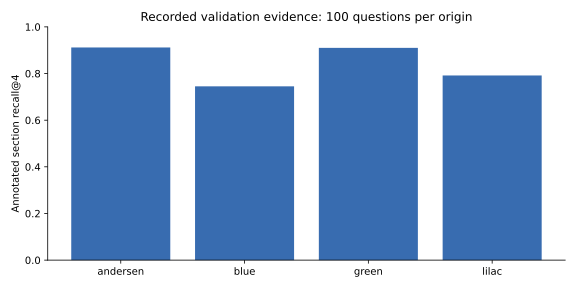

Evidence relevance is not answer accuracy; token truncation is not measured by this plot.


In [12]:
recorded_retrieval=read_json("docs/v5-validation-retrieval-baseline.json")
if (STAGED/"manifest.json").exists():
    validation_stories,validation_questions=load_split(STAGED,"validation")
    cohort=validation_cohort(validation_questions)
    measured=[]
    examples=[]
    for q in cohort:
        story=validation_stories[q["story"]]
        selected=retrieve(q["question"],story["sections"])
        metrics=evidence_metrics([story["sections"][i]["id"] for i in selected],q["gold_sections"])
        measured.append(metrics)
        if len(examples)<3:
            exact=all(story["text"][story["sections"][i]["start"]:story["sections"][i]["end"]]==story["sections"][i]["text"] for i in selected)
            examples.append({"source QA ID":q["id"],"selected sections":str([story["sections"][i]["id"] for i in selected]),"gold-section recall":round(metrics["recall"],3),"source slices exact":exact})
    actual_recall=sum(r["recall"] for r in measured)/len(measured)
    assert abs(actual_recall-recorded_retrieval["recall_at_4"])<1e-12
    table(examples,list(examples[0]),"Actually recomputed validation retrieval; no private question/answer text displayed")
    print("Actual validation evidence recall@4:",round(actual_recall,6),"n=",len(measured))
else:
    print("Private source absent; showing the recorded aggregate, not claiming new retrieval.")
fig,ax=plt.subplots(figsize=(8,4))
origins=list(recorded_retrieval["per_origin"])
ax.bar([o.replace("-fairybook","") for o in origins],[recorded_retrieval["per_origin"][o]["recall_at_4"] for o in origins],color="#386cb0")
ax.set(ylim=(0,1),ylabel="Annotated section recall@4",title="Recorded validation evidence: 100 questions per origin")
show_figure(fig,"main-validation-evidence")
print("Evidence relevance is not answer accuracy; token truncation is not measured by this plot.")


## 4. Generator, loss and complete optimization loop

The loop below loads pinned T5-small safetensors, rejects missing parameters,
trains with real supervised targets, accumulates gradients, clips, evaluates and
saves the best validation checkpoint. Training uses annotated evidence; primary
validation does not inject it. These are normal Python definitions, not wrappers.


In [13]:
def train_narrative(args):
    if args.micro_batch < 1 or args.threads < 1:
        raise ValueError("Microbatch and thread counts must be positive")
    import torch
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer, DataCollatorForSeq2Seq
    from torch.utils.data import DataLoader
    output = Path(args.output)
    if output.exists():
        raise ValueError("Refusing to overwrite training evidence")
    output.mkdir(parents=True)
    policy = json.loads(Path(args.protocol).read_text(encoding="utf-8"))
    spec = policy["generator"]
    torch.set_num_threads(args.threads)
    seed_all(spec["seed"])
    train_stories, train = load_split(args.data, "train")
    valid_stories, valid = load_split(args.data, "validation")
    valid = validation_cohort(valid)
    if args.smoke:
        train, valid = train[:4], valid[:2]
    tokenizer = AutoTokenizer.from_pretrained(spec["name"], revision=spec["revision"], use_fast=True)
    model, loading = AutoModelForSeq2SeqLM.from_pretrained(
        spec["name"], revision=spec["revision"], output_loading_info=True,
        use_safetensors=True)
    if loading.get("missing_keys") or loading.get("mismatched_keys") or loading.get("error_msgs"):
        raise ValueError(f"Incomplete generator checkpoint: {loading}")
    device = "cuda" if torch.cuda.is_available() else "cpu"
    model.to(device)
    model.gradient_checkpointing_enable()
    model.config.use_cache = False
    import importlib.metadata
    import platform
    from huggingface_hub import hf_hub_download
    weights = Path(hf_hub_download(spec["name"], "model.safetensors", revision=spec["revision"]))
    provenance = {"protocol_sha256": sha(Path(args.protocol).read_bytes()),
                  "manifest_sha256": sha((Path(args.data) / "manifest.json").read_bytes()),
                  "model": spec, "loading_info": loading, "device": device,
                  "train_questions": len(train), "validation_questions": len(valid),
                  "validation_ids": [q["id"] for q in valid],
                  "torch": torch.__version__, "smoke": args.smoke,
                  "pretrained_weights_sha256": sha(weights.read_bytes()),
                  "python": platform.python_version(),
                  "environment": {package: importlib.metadata.version(package)
                                  for package in ("transformers", "tokenizers", "numpy", "huggingface-hub")},
                  "source_sha256": sha(NOTEBOOK_PATH.read_bytes())}
    (output / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
    baseline_predictions, baseline = evaluate(model, tokenizer, valid_stories, valid)
    (output / "baseline-private.json").write_text(json.dumps(baseline_predictions), encoding="utf-8")
    results = [{"epoch": 0, "validation": baseline}]
    rows = []
    for q in train:
        story = train_stories[q["story"]]
        # Real human-linked evidence only for supervised reader training. Primary
        # validation/test retrieval has no gold injection. Mixed-context ablation
        # is a separate optional hypothesis, not hidden here.
        indices = [i for i, s in enumerate(story["sections"]) if s["id"] in q["gold_sections"]]
        context, _ = assemble(q["question"], story["sections"], indices, tokenizer,
                              spec["input_tokens"])
        row = tokenizer(context)
        row["labels"] = tokenizer(text_target=q["references"][0], max_length=96,
                                   truncation=True)["input_ids"]
        rows.append(row)
    collator = DataCollatorForSeq2Seq(tokenizer, model=model, padding=True)
    loader = DataLoader(rows, batch_size=args.micro_batch, shuffle=True, collate_fn=collator)
    accumulation = spec["effective_batch_size"] // args.micro_batch
    if accumulation < 1 or accumulation * args.micro_batch != spec["effective_batch_size"]:
        raise ValueError("Microbatch must divide effective batch size")
    optimizer = torch.optim.AdamW(model.parameters(), lr=spec["learning_rate"], weight_decay=0.01)
    scaler = torch.amp.GradScaler("cuda", enabled=device == "cuda")
    epochs = 1 if args.smoke else spec["epochs"]
    best = None
    began = time.monotonic()
    for epoch in range(1, epochs + 1):
        model.train()
        optimizer.zero_grad()
        loss_sum = 0.0
        for step, batch in enumerate(loader, 1):
            batch = {k: v.to(device) for k, v in batch.items()}
            with torch.autocast(device_type=device, dtype=torch.float16, enabled=device == "cuda"):
                loss = model(**batch).loss
            if not torch.isfinite(loss):
                raise ValueError("Nonfinite training loss")
            loss_sum += float(loss.detach())
            # Correct partial final accumulation group, rather than underweighting it.
            group_start = ((step - 1) // accumulation) * accumulation
            divisor = min(accumulation, len(loader) - group_start)
            scaler.scale(loss / divisor).backward()
            if step % accumulation == 0 or step == len(loader):
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad()
            if step % 100 == 0:
                print(json.dumps({"epoch": epoch, "microstep": step, "loss": loss_sum / step,
                                  "seconds": time.monotonic() - began}), flush=True)
        predictions, metrics = evaluate(model, tokenizer, valid_stories, valid)
        results.append({"epoch": epoch, "loss": loss_sum / len(loader), "validation": metrics,
                        "seconds": time.monotonic() - began})
        (output / f"validation-epoch-{epoch}-private.json").write_text(json.dumps(predictions), encoding="utf-8")
        if best is None or metrics["f1"] > best["validation"]["f1"]:
            best = results[-1]
            model.save_pretrained(output / "selected-checkpoint", safe_serialization=True)
            tokenizer.save_pretrained(output / "selected-checkpoint")
        (output / "validation-results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
    checkpoint = output / "selected-checkpoint"
    selection = {"status": "frozen", "checkpoint": str(checkpoint), "selected": best,
                 "weights_sha256": sha((checkpoint / "model.safetensors").read_bytes()),
                 "retrieval": "BM25 top4", "smoke": args.smoke,
                 "provenance_sha256": sha((output / "provenance.json").read_bytes())}
    selection_path = output / "selection.json"
    selection_path.write_text(json.dumps(selection, indent=2), encoding="utf-8")
    if args.smoke:
        # Exercise real persisted-weight loading and deterministic answer equality.
        # The optimizer/collator retain parameter references, so release them too.
        import gc
        del optimizer, scaler, loader, collator, model
        gc.collect()
        reloaded = AutoModelForSeq2SeqLM.from_pretrained(checkpoint, local_files_only=True,
                                                       use_safetensors=True).to(device)
        repeated, _ = evaluate(reloaded, tokenizer, valid_stories, valid)
        expected = json.loads((output / "validation-epoch-1-private.json").read_text())
        equal = [r["answer"] for r in repeated] == [r["answer"] for r in expected]
        (output / "reload-check.json").write_text(json.dumps({"answers_identical": equal,
                                                              "questions": len(repeated)}))
        if not equal:
            raise ValueError("Saved checkpoint reload changed deterministic smoke answers")
    # Smoke never opens test QA. Real test is a separate explicit command and
    # exclusive output marker, so a failed test is preserved rather than rerun.
    print(json.dumps({"selected_epoch": best["epoch"], "validation": best["validation"],
                      "test_accessed": False}), flush=True)


In [14]:
smoke=read_json("docs/v5-cpu-smoke.json")
table([{"check":"missing pretrained keys","value":len(smoke["loading_info"]["missing_keys"])},
       {"check":"unexpected keys","value":len(smoke["loading_info"]["unexpected_keys"])},
       {"check":"mismatched keys","value":len(smoke["loading_info"]["mismatched_keys"])},
       {"check":"CPU smoke seconds","value":round(smoke["runtime"]["wall_seconds"],2)},
       {"check":"actual mean training loss","value":round(smoke["train_loss"],5)},
       {"check":"save/reload identical answers","value":smoke["checkpoint_reload"]["answers_identical"]}],
      ["check","value"],"Actual 4-train/2-validation CPU mechanics run; not a performance benchmark")
if RUN_TRAIN:
    train_narrative(SimpleNamespace(data=STAGED,output=RUN_DIR,protocol=PROTOCOL,micro_batch=2,threads=4,smoke=False))
else:
    print("Full cloud training is running separately. This notebook has not retrained it.")


check,value
missing pretrained keys,0
unexpected keys,0
mismatched keys,0
CPU smoke seconds,79.77
actual mean training loss,0.4628
save/reload identical answers,True


Full cloud training is running separately. This notebook has not retrained it.


## 5. Evidence-supervised reranker

Every annotated positive forms a group with same-story hard negatives; other
gold sections never become negatives. Nonlinked evidence can still be valid,
so these labels are imperfect. The following code includes the actual model,
contrastive loss, optimizer and validation checkpoint selection.


In [15]:
def build_groups(stories, questions, seed=42):
    groups = []
    skipped = 0
    for question in questions:
        sections = stories[question["story"]]["sections"]
        gold = set(question["gold_sections"])
        order = lexical_ranking(question["question"], sections)
        negatives = [i for i in order if sections[i]["id"] not in gold]
        if not negatives:
            skipped += 1
            continue
        chosen = negatives[:3]
        rest = negatives[3:]
        if rest:
            rng = random.Random(seed + int(sha(question["id"].encode())[:12], 16))
            chosen.append(rng.choice(rest))
        for positive, section in enumerate(sections):
            if section["id"] in gold:
                indices = [positive] + chosen
                groups.append({"id": question["id"], "positive_section": section["id"],
                               "section_ids": [sections[i]["id"] for i in indices],
                               "pairs": [(question["question"], sections[i]["text"]) for i in indices]})
    return groups, skipped


class SectionReranker:
    def __init__(self, model, tokenizer, max_tokens=384, batch_size=8):
        if type(max_tokens) is not int or max_tokens < 16 or type(batch_size) is not int or batch_size < 1:
            raise ValueError("Positive ranking batch size and context capacity required")
        self.model = model
        self.tokenizer = tokenizer
        self.max_tokens = max_tokens
        self.batch_size = batch_size

    def predict(self, pairs, **unused):
        import numpy as np
        import torch
        self.model.eval()
        scores = []
        if any(len(self.tokenizer.encode(p[0], add_special_tokens=False)) > self.max_tokens - 8 for p in pairs):
            raise ValueError("Question exceeds ranking token capacity")
        for start in range(0, len(pairs), self.batch_size):
            batch = pairs[start:start + self.batch_size]
            encoded = self.tokenizer([p[0] for p in batch], [p[1] for p in batch],
                                     max_length=self.max_tokens, padding=True,
                                     truncation="only_second", return_tensors="pt").to(self.model.device)
            with torch.inference_mode():
                logits = self.model(**encoded).logits[:, 0]
            if not torch.isfinite(logits).all():
                raise ValueError("Nonfinite section-reranker logits")
            scores.extend(logits.cpu().tolist())
        return np.asarray(scores)


def evaluate_sections(stories, questions, reranker=None, cases_path=None):
    rows = []
    for question in questions:
        sections = stories[question["story"]]["sections"]
        indices = retrieve(question["question"], sections, reranker)
        selected = [sections[i]["id"] for i in indices]
        candidates = [sections[i]["id"] for i in lexical_ranking(question["question"], sections)[:12]]
        metrics = evidence_metrics(selected, question["gold_sections"])
        rows.append({"id": question["id"], "story": question["story"],
                     "selected_sections": selected, "gold_sections": question["gold_sections"],
                     "candidate_sections": candidates,
                     "origin": question["origin"], "attribute": question["attribute"],
                     "explicit": question["explicit"], **metrics,
                     "candidate_recall": evidence_metrics(candidates, question["gold_sections"])["recall"],
                     "top4_ceiling": min(4, len(question["gold_sections"])) / len(question["gold_sections"])})
    report = {"n": len(rows), "recall_at_4": sum(r["recall"] for r in rows) / len(rows),
              "precision_at_4": sum(r["precision"] for r in rows) / len(rows),
              "candidate_recall_at_12": sum(r["candidate_recall"] for r in rows) / len(rows),
              "annotation_top4_ceiling": sum(r["top4_ceiling"] for r in rows) / len(rows)}
    for group in ("origin", "attribute", "explicit"):
        report[group] = {value: {"n": sum(r[group] == value for r in rows),
            "recall_at_4": sum(r["recall"] for r in rows if r[group] == value) /
                           sum(r[group] == value for r in rows)}
            for value in sorted(set(r[group] for r in rows))}
    if cases_path is not None:
        with Path(cases_path).open("x", encoding="utf-8") as handle:
            json.dump(rows, handle)
    return report


def train_reranker(args):
    import importlib.metadata
    import platform
    import torch
    from huggingface_hub import hf_hub_download
    from transformers import AutoModelForSequenceClassification, AutoTokenizer
    output = Path(args.output)
    if output.exists():
        raise ValueError("Refusing to overwrite reranker evidence")
    policy = json.loads(Path(args.protocol).read_text(encoding="utf-8"))
    spec, training = policy["model"], policy["training"]
    manifest_path = Path(args.data) / "manifest.json"
    if sha(manifest_path.read_bytes()) != policy["source"]["dataset_manifest_sha256"]:
        raise ValueError("Prespecified dataset manifest changed")
    stories, train = load_split(args.data, "train")
    validation_stories, validation = load_split(args.data, "validation")
    validation = validation_cohort(validation)
    if sha(json.dumps([q["id"] for q in validation]).encode()) != policy["source"]["validation_ids_sha256"]:
        raise ValueError("Prespecified validation cohort changed")
    if args.smoke:
        train, validation = train[:4], validation[:2]
    groups, skipped = build_groups(stories, train, spec["seed"])
    if not groups:
        raise ValueError("No real supervised ranking groups")
    torch.set_num_threads(4)
    seed_all(spec["seed"])
    tokenizer = AutoTokenizer.from_pretrained(spec["name"], revision=spec["revision"], use_fast=True)
    model, info = AutoModelForSequenceClassification.from_pretrained(
        spec["name"], revision=spec["revision"], use_safetensors=True, output_loading_info=True)
    if info.get("missing_keys") or info.get("unexpected_keys") or info.get("mismatched_keys") or info.get("error_msgs"):
        raise ValueError("Incomplete or incompatible pretrained ranking head: " + str(info))
    if model.config.num_labels != 1:
        raise ValueError("Expected one pretrained ranking logit")
    model.to("cpu")
    model.gradient_checkpointing_enable()
    scorer = SectionReranker(model, tokenizer, spec["max_tokens"])
    weights = Path(hf_hub_download(spec["name"], "model.safetensors", revision=spec["revision"]))
    target_lengths = [len(tokenizer(p[0], p[1], add_special_tokens=True)["input_ids"])
                      for group in groups for p in group["pairs"]]
    output.mkdir(parents=True)
    provenance = {"model": spec, "training": training, "loading_info": info,
                  "pretrained_weights_sha256": sha(weights.read_bytes()),
                  "protocol_sha256": sha(Path(args.protocol).read_bytes()),
                  "manifest_sha256": sha(manifest_path.read_bytes()),
                  "train_questions": len(train), "training_groups": len(groups),
                  "training_pairs": len(target_lengths), "questions_without_negatives": skipped,
                  "pair_truncations": sum(n > spec["max_tokens"] for n in target_lengths),
                  "validation_questions": len(validation), "smoke": args.smoke,
                  "python": platform.python_version(), "torch": torch.__version__,
                  "environment": {name: importlib.metadata.version(name)
                                  for name in ("transformers", "numpy", "tokenizers", "huggingface-hub")},
                  "source_sha256": sha(NOTEBOOK_PATH.read_bytes()), "test_accessed": False}
    (output / "provenance.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
    results = [{"kind": "bm25", "epoch": 0, "validation": evaluate_sections(validation_stories, validation,
                    cases_path=output / "bm25-validation-private.json")},
               {"kind": "pretrained", "epoch": 0,
                "validation": evaluate_sections(validation_stories, validation, scorer,
                    output / "pretrained-validation-private.json")}]
    optimizer = torch.optim.AdamW(model.parameters(), lr=training["learning_rate"],
                                 weight_decay=training["weight_decay"])
    accumulation = training["effective_groups"] // training["micro_groups"]
    best_adapted = None
    began = time.monotonic()
    for epoch in range(1, (1 if args.smoke else training["epochs"]) + 1):
        order = list(groups)
        random.Random(spec["seed"] + epoch).shuffle(order)
        batches = [order[i:i + training["micro_groups"]] for i in range(0, len(order), training["micro_groups"])]
        model.train()
        optimizer.zero_grad()
        loss_sum = 0.0
        for step, batch in enumerate(batches, 1):
            pairs = [p for group in batch for p in group["pairs"]]
            encoded = tokenizer([p[0] for p in pairs], [p[1] for p in pairs], padding=True,
                                truncation="only_second", max_length=spec["max_tokens"], return_tensors="pt")
            logits = model(**encoded).logits[:, 0]
            if not torch.isfinite(logits).all():
                raise ValueError("Nonfinite ranking training logits")
            losses, offset = [], 0
            for group in batch:
                count = len(group["pairs"])
                losses.append(-torch.log_softmax(logits[offset:offset + count], dim=0)[0])
                offset += count
            loss = torch.stack(losses).mean()
            if not torch.isfinite(loss):
                raise ValueError("Nonfinite ranking training loss")
            loss_sum += float(loss.detach())
            group_start = ((step - 1) // accumulation) * accumulation
            divisor = min(accumulation, len(batches) - group_start)
            (loss / divisor).backward()
            if step % accumulation == 0 or step == len(batches):
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()
                optimizer.zero_grad()
            if step % 100 == 0:
                print(json.dumps({"epoch": epoch, "microstep": step, "loss": loss_sum / step,
                                  "seconds": time.monotonic() - began}), flush=True)
        metrics = evaluate_sections(validation_stories, validation, scorer,
                                    output / f"adapted-epoch-{epoch}-validation-private.json")
        row = {"kind": "adapted", "epoch": epoch, "validation": metrics,
               "train_loss": loss_sum / len(batches), "seconds": time.monotonic() - began}
        results.append(row)
        if best_adapted is None or metrics["recall_at_4"] > best_adapted["validation"]["recall_at_4"]:
            best_adapted = row
            model.save_pretrained(output / "adapted-checkpoint", safe_serialization=True)
            tokenizer.save_pretrained(output / "adapted-checkpoint")
        (output / "validation-results.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
    # Stable max preserves declared simplicity/earlier-epoch tie order.
    selected = max(results, key=lambda r: r["validation"]["recall_at_4"])
    selection = {"status": "frozen", "selected": selected, "best_adapted": best_adapted,
                 "model": spec, "smoke": args.smoke, "test_accessed": False,
                 "adapted_weights_sha256": sha((output / "adapted-checkpoint/model.safetensors").read_bytes()),
                 "provenance_sha256": sha((output / "provenance.json").read_bytes())}
    (output / "selection.json").write_text(json.dumps(selection, indent=2), encoding="utf-8")
    if args.smoke:
        import gc
        reference_scores = scorer.predict(groups[0]["pairs"])
        del scorer, optimizer, model
        gc.collect()
        reloaded = AutoModelForSequenceClassification.from_pretrained(output / "adapted-checkpoint",
            local_files_only=True, use_safetensors=True)
        repeated = SectionReranker(reloaded, tokenizer).predict(groups[0]["pairs"])
        import numpy as np
        difference = float(np.max(np.abs(reference_scores - repeated)))
        (output / "reload-check.json").write_text(json.dumps({"max_logit_difference": difference}))
        if difference > 1e-6:
            raise ValueError("Saved ranking checkpoint changed logits")
    print(json.dumps({"selection": selected, "test_accessed": False}), flush=True)


In [16]:
r=read_json("docs/v5-reranker-data-preflight.json")
table([{k:r[k] for k in ["train_questions","training_groups","training_pairs","questions_without_nongold_negative","test_accessed"]}],
      ["train_questions","training_groups","training_pairs","questions_without_nongold_negative","test_accessed"],
      "Actually constructed train-only groups; reranker outcomes are not yet available")
if RUN_RERANKER_TRAIN:
    train_reranker(SimpleNamespace(data=STAGED,output=RUN_DIR.with_name(RUN_DIR.name+"-reranker"),protocol=ROOT/"docs/v5-reranker-protocol.json",smoke=False))


train_questions,training_groups,training_pairs,questions_without_nongold_negative,test_accessed
3314,3770,18660,3,False


## 6. Reader and exact citation checks

The historical extractive reader is retained with its poor scores. Its output is
a literal source span. Generated answers use a separate schema and must never
be represented as exact spans. Both attribution paths are directly visible.


In [17]:
def validate_loading_info(info):
    if any(info.get(key) for key in ('missing_keys', 'mismatched_keys', 'error_msgs')):
        raise ValueError('Pretrained QA checkpoint has missing, mismatched or erroneous parameters')
    expected_unused = {'bert.pooler.dense.weight', 'bert.pooler.dense.bias'}
    if set(info.get('unexpected_keys', [])) - expected_unused:
        raise ValueError('Unexpected pretrained checkpoint parameters')


In [18]:
@lru_cache(maxsize=1)
def reader():
    import torch
    from transformers import AutoTokenizer, AutoModelForQuestionAnswering
    torch.set_num_threads(2)
    tokenizer=AutoTokenizer.from_pretrained(MODEL,revision=REVISION,trust_remote_code=False)
    model,loading_info=AutoModelForQuestionAnswering.from_pretrained(MODEL,revision=REVISION,trust_remote_code=False,use_safetensors=True,output_loading_info=True)
    validate_loading_info(loading_info)
    model.eval()
    return tokenizer,model


def candidates(question,passages,sliding=False,max_length=384,stride=96,batch_size=8):
    import torch
    if not passages:return []
    if not isinstance(question,str) or not question.strip():return []
    if not 128<=max_length<=512 or not 0<=stride<max_length//2 or batch_size<1:
        raise ValueError('Invalid reader window or batch configuration')
    tokenizer,model=reader()
    if len(tokenizer.encode(question,add_special_tokens=False))>max_length-32:
        return []
    options={'return_overflowing_tokens':True,'stride':stride} if sliding else {}
    encoded=tokenizer([question]*len(passages),[p.text for p in passages],padding=True,truncation='only_second',max_length=max_length,return_offsets_mapping=True,return_tensors='pt',**options)
    mapping=encoded.pop('overflow_to_sample_mapping').tolist() if sliding else list(range(len(passages)))
    offsets=encoded.pop('offset_mapping').tolist()
    starts_all=[];ends_all=[]
    for lo in range(0,len(mapping),batch_size):
        batch={key:value[lo:lo+batch_size] for key,value in encoded.items()}
        with torch.inference_mode():output=model(**batch)
        starts_all.extend(output.start_logits);ends_all.extend(output.end_logits)
    result=[]
    for row,passage_id in enumerate(mapping):
        p=passages[passage_id]
        context=[i for i,seq in enumerate(encoded.sequence_ids(row)) if seq==1 and offsets[row][i][1]>offsets[row][i][0]]
        if not context:continue
        starts=starts_all[row];ends=ends_all[row]
        if not torch.isfinite(starts).all() or not torch.isfinite(ends).all():
            continue
        top_starts=sorted(context,key=lambda i:-float(starts[i]))[:20]
        top_ends=sorted(context,key=lambda i:-float(ends[i]))[:20]
        valid=[(float(starts[a]+ends[b]),a,b) for a in top_starts for b in top_ends if a<=b<a+30]
        if not valid:continue
        score,a,b=max(valid)
        cls=(encoded['input_ids'][row]==tokenizer.cls_token_id).nonzero()[0].item()
        margin=score-float(starts[cls]+ends[cls])
        start,end=offsets[row][a][0],offsets[row][b][1]
        result.append({'answer':p.text[start:end],'citation':p.id,'book':p.book,'answer_start':p.start+start,'answer_end':p.start+end,'null_margin':margin,'reader_window':row,'retrieval_rank':passage_id+1})
    return sorted(result,key=lambda r:-r['null_margin'])


In [19]:
def expand_passage(passage,text,characters=700):
    if not isinstance(characters,int) or characters<0:
        raise ValueError('Expansion must be a nonnegative integer')
    if text[passage.start:passage.end]!=passage.text:
        raise ValueError('Cannot expand a passage that mismatches its source')
    start=max(0,passage.start-characters)
    end=min(len(text),passage.end+characters)
    # Avoid cutting words while retaining exact source coordinates.
    while start>0 and not text[start-1].isspace():start-=1
    while end<len(text) and not text[end].isspace():end+=1
    return Passage(f'{passage.book}:{start}-{end}',passage.book,start,end,text[start:end],passage.progress)


def select_span(spans,threshold=0,rank_penalty=0):
    if not math.isfinite(threshold) or not math.isfinite(rank_penalty) or rank_penalty<0:
        raise ValueError('Threshold and nonnegative rank penalty must be finite')
    eligible=[s for s in spans if math.isfinite(s['null_margin']) and s['null_margin']>threshold
              and isinstance(s.get('retrieval_rank',1),int) and s.get('retrieval_rank',1)>=1]
    if not eligible:return None
    return max(eligible,key=lambda s:s['null_margin']-rank_penalty*(s.get('retrieval_rank',1)-1))


def assemble_span_answer(span,passages,book):
    if span is None:return {'abstained':True,'answer':None,'reason':'No span exceeded the frozen null threshold'}
    known={p.id:p for p in passages}
    passage=known.get(span['citation'])
    if passage is None or passage.book!=book or span.get('book')!=book:
        return {'abstained':True,'answer':None,'reason':'Span source is absent or belongs to another book'}
    start=span['answer_start']-passage.start;end=span['answer_end']-passage.start
    if not 0<=start<end<=len(passage.text) or passage.text[start:end]!=span['answer']:
        return {'abstained':True,'answer':None,'reason':'Answer does not exactly match cited source coordinates'}
    return {**span,'abstained':False,'evidence':{'citation':passage.id,'answer_start':span['answer_start'],'answer_end':span['answer_end']},'citation_method':'Deterministically assembled from exact source offsets; no model-generated quote JSON','semantic_correctness_verified':False}


In [20]:
def finite_number(value):
    if type(value) not in (int,float):
        return False
    try:
        return math.isfinite(value)
    except OverflowError:
        return False


def digest_policy(policy):
    raw = json.dumps(policy, sort_keys=True, separators=(',', ':'),
                     ensure_ascii=False, allow_nan=False).encode('utf-8')
    return hashlib.sha256(raw).hexdigest()


def policy_from_selection(selection):
    if (not isinstance(selection,dict) or not isinstance(selection.get('selected'),dict)
            or not isinstance(selection.get('models'),dict)):
        raise ValueError('Frozen selection must contain models and selected policy objects')
    selected = selection['selected']
    if not {'config','threshold','rank_penalty'} <= set(selected):
        raise ValueError('Frozen selection is missing required policy fields')
    policy={'models': selection['models'], 'config': selected['config'],
            'threshold': selected['threshold'], 'rank_penalty': selected['rank_penalty']}
    validate_policy(policy)
    return policy


def validate_policy(policy):
    if not isinstance(policy,dict) or not {'models','config','threshold','rank_penalty'} <= set(policy):
        raise ValueError('Answer policy must contain required policy fields')
    if (not finite_number(policy['threshold']) or not finite_number(policy['rank_penalty'])
            or policy['rank_penalty'] < 0):
        raise ValueError('Invalid finite selection parameters')
    config = policy['config']
    if not isinstance(config,dict) or not {'words','overlap','k','expand','sliding'} <= set(config):
        raise ValueError('Answer policy has incomplete chunk configuration')
    if (type(config['words']) is not int or type(config['overlap']) is not int
            or not 0 <= config['overlap'] < config['words']
            or type(config['k']) is not int or config['k'] < 1
            or type(config['expand']) is not int or config['expand'] < 0
            or type(config['sliding']) is not bool):
        raise ValueError('Invalid persisted chunk or reader configuration')
    models = policy['models']
    if (not isinstance(models,dict) or not isinstance(models.get('reader'),str) or not models['reader']
            or any(not isinstance(models.get(key),str) or not re.fullmatch(r'[0-9a-f]{40}',models[key])
                   for key in ('embedding_revision','reader_revision','reranker_revision'))):
        raise ValueError('Missing exact persisted model revisions')


def verify_artifact(artifact, text, expected_selection=None):
    if not isinstance(artifact,dict):
        raise ValueError('Answer artifact must be an object')
    if not isinstance(text,str):
        raise ValueError('Source must be Unicode text')
    if not {'policy','policy_sha256','source_sha256','book','abstained'} <= set(artifact):
        raise ValueError('Answer artifact is missing required fields')
    if type(artifact.get('artifact_schema')) is not int or artifact['artifact_schema'] != 1:
        raise ValueError('Unsupported answer artifact schema')
    book = artifact.get('book')
    if not isinstance(book, str) or not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]*', book):
        raise ValueError('Invalid source book identifier')
    if artifact.get('source_sha256') != hashlib.sha256(text.encode('utf-8')).hexdigest():
        raise ValueError('Answer source fingerprint changed')
    policy = artifact['policy']
    validate_policy(policy)
    if artifact.get('policy_sha256') != digest_policy(policy):
        raise ValueError('Answer policy fingerprint changed')
    if expected_selection is not None and policy != policy_from_selection(expected_selection):
        raise ValueError('Artifact differs from the expected frozen selection')
    config = policy['config']
    if type(artifact.get('abstained')) is not bool:
        raise ValueError('Abstention status must be explicit')
    if artifact['abstained']:
        if artifact.get('answer') is not None or any(key in artifact for key in ('citation', 'answer_start', 'answer_end')):
            raise ValueError('Abstention cannot carry an accepted answer')
        return {'valid': True, 'abstained': True, 'source_exact': None,
                'frozen_policy_matches': expected_selection is not None,
                'semantic_correctness_verified': False, 'authenticity_verified': False}
    answer, start, end = artifact.get('answer'), artifact.get('answer_start'), artifact.get('answer_end')
    citation = artifact.get('citation')
    match = re.fullmatch(r'([A-Za-z0-9][A-Za-z0-9_-]*):(\d+)-(\d+)', citation) if isinstance(citation, str) else None
    if (not match or match[1] != book or type(start) is not int or type(end) is not int
            or not 0 <= int(match[2]) <= start < end <= int(match[3]) <= len(text)
            or not isinstance(answer, str) or text[start:end] != answer):
        raise ValueError('Answer does not match cited source coordinates')
    if (not finite_number(artifact.get('null_margin')) or artifact['null_margin'] <= policy['threshold']
            or type(artifact.get('retrieval_rank')) is not int
            or not 1 <= artifact['retrieval_rank'] <= config['k']):
        raise ValueError('Answer lacks finite eligible reader provenance')
    expected_evidence = {'citation': citation, 'answer_start': start, 'answer_end': end}
    if artifact.get('evidence') != expected_evidence:
        raise ValueError('Evidence metadata disagrees with answer coordinates')
    passages = chunk_book(book, text, config['words'], config['overlap'])
    known = {expand_passage(p, text, config['expand']).id if config['expand'] else p.id for p in passages}
    if citation not in known:
        raise ValueError('Citation does not match declared source chunk geometry')
    return {'valid': True, 'abstained': False, 'source_exact': True,
            'frozen_policy_matches': expected_selection is not None,
            'selection_decision_recomputed': False, 'semantic_correctness_verified': False,
            'authenticity_verified': False}


def make_artifact(result, text, book, selection):
    if not isinstance(result,dict):
        raise ValueError('Answer result must be an object')
    policy = policy_from_selection(selection)
    artifact = {**result, 'artifact_schema': 1, 'book': book,
                'source_sha256': hashlib.sha256(text.encode('utf-8')).hexdigest(),
                'policy': policy, 'policy_sha256': digest_policy(policy)}
    verify_artifact(artifact, text, selection)
    return artifact


def audit_answer(path, source_directory, expected_selection=None):
    def unique_pairs(pairs):
        result = {}
        for key, value in pairs:
            if key in result:
                raise ValueError('Duplicate answer artifact key')
            result[key] = value
        return result
    with Path(path).open('rb') as source:
        raw = source.read(1_000_001)
    if len(raw) > 1_000_000:
        raise ValueError('Answer artifact is unexpectedly large')
    artifact = json.loads(raw.decode('utf-8'), object_pairs_hook=unique_pairs)
    if not isinstance(artifact,dict):
        raise ValueError('Answer artifact must be an object')
    book = artifact.get('book')
    if not isinstance(book, str) or not re.fullmatch(r'[A-Za-z0-9][A-Za-z0-9_-]*', book):
        raise ValueError('Invalid source book identifier')
    text = (Path(source_directory) / f'{book}.txt').read_text(encoding='utf-8')
    return verify_artifact(artifact, text, expected_selection)


In [21]:
def grounded_reader_answer(index, question, book, source_directory, selection):
    """Apply a frozen validation policy to a verified persisted index."""
    from pathlib import Path
    if not isinstance(question, str) or not question.strip():
        return {'abstained': True, 'answer': None, 'reason': 'Empty question'}
    if len(question) > 1000:
        return {'abstained': True, 'answer': None, 'reason': 'Question exceeds the supported 1000-character limit'}
    if book not in {p.book for p in index.passages}:
        return {'abstained': True, 'answer': None, 'reason': 'Requested source is not indexed'}
    index.verify_sources(Path(source_directory))
    models = selection['models']
    if (index.backend != 'sentence-transformer'
            or index.model_name != 'sentence-transformers/all-MiniLM-L6-v2'
            or index.model_revision != models['embedding_revision']
            or models['reader'] != MODEL or models['reader_revision'] != REVISION
            or models['reranker_revision'] != RERANKER_REVISION):
        raise ValueError('Index or reader model differs from the frozen selection')
    policy = selection['selected']
    config = policy['config']
    index.verify_chunk_contract(Path(source_directory),config['words'],config['overlap'])
    hits = index.search(question, book=book, k=config['k'],
                        reranker='cross-encoder/ms-marco-MiniLM-L-6-v2')
    text = (Path(source_directory) / f'{book}.txt').read_text(encoding='utf-8')
    passages = [expand_passage(p, text, config['expand']) if config['expand'] else p
                for p, _ in hits]
    spans = candidates(question, passages, sliding=config['sliding'])
    result=assemble_span_answer(select_span(spans, policy['threshold'], policy['rank_penalty']),passages,book)
    return make_artifact(result,text,book,selection)


In [22]:
def verify_run(folder, allow_smoke=False):
    folder = Path(folder)
    selection = json.loads((folder / "selection.json").read_text(encoding="utf-8"))
    if not isinstance(selection, dict):
        raise ValueError("Expected a selection JSON object")
    if selection.get("status") != "frozen" or (selection.get("smoke") and not allow_smoke):
        raise ValueError("A full frozen training selection is required")
    provenance_path = folder / "provenance.json"
    if sha(provenance_path.read_bytes()) != selection.get("provenance_sha256"):
        raise ValueError("Training provenance changed")
    checkpoint = folder / "selected-checkpoint"
    if sha((checkpoint / "model.safetensors").read_bytes()) != selection.get("weights_sha256"):
        raise ValueError("Selected weights changed")
    return checkpoint, selection


def load_selected(folder, allow_smoke=False):
    checkpoint, selection = verify_run(folder, allow_smoke)
    import torch
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(checkpoint, local_files_only=True, use_fast=True)
    model, info = AutoModelForSeq2SeqLM.from_pretrained(
        checkpoint, local_files_only=True, use_safetensors=True, output_loading_info=True)
    if info.get("missing_keys") or info.get("mismatched_keys") or info.get("error_msgs"):
        raise ValueError("Incomplete trained generator checkpoint")
    model.to("cuda" if torch.cuda.is_available() else "cpu").eval()
    return model, tokenizer, selection


def verify_story(story):
    if not isinstance(story, dict) or not isinstance(story.get("text"), str):
        raise ValueError("Expected a story with source text")
    if sha(story["text"].encode()) != story.get("source_sha256"):
        raise ValueError("Story source hash mismatch")
    sections = story.get("sections")
    if not isinstance(sections, list) or not sections:
        raise ValueError("Story must contain source sections")
    for section in sections:
        if not isinstance(section, dict):
            raise ValueError("Expected a source section object")
        start, end = section.get("start"), section.get("end")
        if type(start) is not int or type(end) is not int or not 0 <= start < end <= len(story["text"]):
            raise ValueError("Invalid source section coordinates")
        if story["text"][start:end] != section.get("text"):
            raise ValueError("Story section source-offset mismatch")
        if not isinstance(section.get("id"), str) or not section["id"]:
            raise ValueError("Source section ID required")
    if len({s["id"] for s in sections}) != len(sections):
        raise ValueError("Duplicate source section IDs")


def generate_narrative_answer(question, story, model, tokenizer, selection):
    if not isinstance(question, str) or not question.strip() or len(question) > 2000:
        raise ValueError("A nonempty question of at most 2000 characters is required")
    verify_story(story)
    indices = retrieve(question, story["sections"])
    context, citations = assemble(question, story["sections"], indices, tokenizer,
                                  min(512, tokenizer.model_max_length))
    import torch
    encoded = tokenizer(context, return_tensors="pt").to(model.device)
    with torch.inference_mode():
        output = model.generate(**encoded, max_new_tokens=96, num_beams=4,
                                do_sample=False, early_stopping=True, use_cache=True)
    return {"schema": "narrative-generated-answer-v1", "answer_kind": "generated",
            "question": question, "answer": tokenizer.decode(output[0], skip_special_tokens=True),
            "story": story["id"], "source_sha256": story["source_sha256"],
            "trained_weights_sha256": selection["weights_sha256"],
            "retrieved_evidence": citations,
            "citation_claim": "Exact source location only; no entailment proof or calibrated no-answer claim"}


In [23]:
artifact_path=DATA/"interim/v4-answer-artifact.json"
if artifact_path.exists() and (DATA/"processed/dorian.txt").exists():
    frozen=read_json("docs/v2-validation-selection.json")
    receipt=audit_answer(artifact_path,DATA/"processed",frozen)
    table([receipt],list(receipt),"Actual persisted historical validation answer replay; no model rerun")
else:
    print("Private artifact absent; no replacement answer is invented.")
if RUN_READER:
    assert "index" in globals(), "Explicitly load and verify a real index first"
    result=grounded_reader_answer(index,"What motivates the character?","dorian",DATA/"processed",read_json("docs/v2-validation-selection.json"))
    print({"abstained":result["abstained"],"has citation":"citation" in result})
if RUN_GENERATED_ANSWER:
    STORY_PATH=None  # Choose an actual processed *.story.json.
    QUESTION=""      # Supply the question you want to ask.
    assert STORY_PATH is not None and QUESTION.strip(), "Configure real source and question"
    model,tokenizer,selection=load_selected(RUN_DIR)
    story=json.loads(Path(STORY_PATH).read_text(encoding="utf-8"))
    generated=generate_narrative_answer(QUESTION,story,model,tokenizer,selection)
    answer_path=DATA/"interim"/(RUN_DIR.name+"-answer.json")
    with answer_path.open("x",encoding="utf-8") as handle:
        json.dump(generated,handle,ensure_ascii=False,indent=2)
    print({"kind":generated["answer_kind"],"source evidence sections":len(generated["retrieved_evidence"]),"private artifact":answer_path.name})


valid,abstained,source_exact,frozen_policy_matches,selection_decision_recomputed,semantic_correctness_verified,authenticity_verified
True,False,True,True,False,False,False


## 7. Held-out evaluation and interpretation

Freeze the final generator and retrieval policy before accessing test QA. The
training dataset has none. The exclusive test marker prevents silent overwrite;
copying an artifact directory does not make an observed test fresh. Dorian,
Persuasion, Call of the Wild, Journey and Cask are already observed.

Valid locations do not prove entailment. Fairy-tale families can share plots and
appear in pretraining. This study does not establish adult novel or cross-book
thematic accuracy. Supporting notebooks show measured distributions, negative
ablations and reliability failures.


In [24]:
def evaluate_frozen_test(data,run_folder):
    # Same one-shot sequence as the CLI, with explicit notebook arguments.
    run_folder=Path(run_folder)
    checkpoint,selection=verify_run(run_folder)
    if selection.get("smoke"):
        raise ValueError("A full selected training run is required")
    selection_path=run_folder/"selection.json"
    with (run_folder/"test-started.json").open("x",encoding="utf-8") as handle:
        json.dump({"selection_sha256":sha(selection_path.read_bytes())},handle)
    test_stories,test_questions=load_split(data,"test",selection_path)
    selected_model,selected_tokenizer,_=load_selected(run_folder)
    predictions,metrics=evaluate(selected_model,selected_tokenizer,test_stories,test_questions)
    (run_folder/"test-private.json").write_text(json.dumps(predictions),encoding="utf-8")
    (run_folder/"test-results.json").write_text(json.dumps(metrics,indent=2),encoding="utf-8")
    return metrics
if RUN_TEST:
    print(evaluate_frozen_test(STAGED,RUN_DIR))
else:
    print("Test QA remains closed; no held-out scoring executed.")


Test QA remains closed; no held-out scoring executed.
